<a href="https://colab.research.google.com/github/tachom-a11/111111/blob/main/ipynb/ex_Perceptrons.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# パーセプトロンの動作について学ぶ（Behavior of perceptrons）
----

氏名：

学生番号：

----
[A Neural Network Playground](http://playground.tensorflow.org/)を用いて，パーセプトロンの振る舞い考察しましょう．
Playground詳しい説明は[ここにあります](https://cloud.google.com/blog/products/ai-machine-learning/understanding-neural-networks-with-tensorflow-playground)．

以下の課題に取り組む際の注意点です．
- "Run/Pause"の左のボタン"Reset the network"を用いて反復試行すること．必ず同じモデルに収束するとは限りません．
- 左下の"[REGENERATE]"で再生成したデータも試すこと．特定のデータについてではなく，普遍的に言える事柄を見つけましょう．
- 十分収束するまで観察すること．学習中のモデルよりも必ず良いモデルに収束するのでしょうか．
- 右下の"Show test data"で表示されるデータ（訓練データ以外のデータ）に対しても識別できているかどうかで評価すること．

特に，訓練データが少なく，ノイズの影響も無視できない問題設定にすると，考察に有益です．  
Ratio of training to test data: 20%，Noise: 25 の設定で実験します．

(a) [モデル：単純パーセプトロン，　データセット："Gaussian"](https://playground.tensorflow.org/#activation=sigmoid&batchSize=10&dataset=gauss&regDataset=reg-plane&learningRate=0.03&regularizationRate=0.01&noise=30&networkShape=&seed=0.85984&showTestData=false&discretize=true&percTrainData=20&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false&batchSize_hide=false)

(b) [モデル：3層パーセプトロン，　データセット："Circle"](https://playground.tensorflow.org/#activation=sigmoid&batchSize=10&dataset=circle&regDataset=reg-plane&learningRate=0.3&regularizationRate=0.01&noise=25&networkShape=1&seed=0.28240&showTestData=false&discretize=true&percTrainData=20&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false&batchSize_hide=false)

(c) [モデル：単純パーセプトロン，データセット："Circle"](https://playground.tensorflow.org/#activation=sigmoid&batchSize=10&dataset=circle&regDataset=reg-plane&learningRate=0.3&regularizationRate=0.01&noise=25&networkShape=&seed=0.64557&showTestData=false&discretize=true&percTrainData=20&x=true&y=true&xTimesY=true&xSquared=true&ySquared=true&cosX=false&sinX=true&cosY=false&sinY=true&collectStats=false&problem=classification&initZero=false&hideText=false&batchSize_hide=false)

まず，(a)で，単純パーセプトロンが線形識別器であることを確認してから，課題に着手しましょう．

----
## 基本課題（必須）

    1. (b)では，中間層に何個以上のノード（neurons）が必要ですか．その理由を述べてください（結果論は不可です）．
      また，多数のノード（例えば8個）で学習を続けると，どのような問題が生じますか．

（ここに回答を書いてください）



    2. (c)のモデルは単純パーセプトロンなのに，決定境界が直線でないのはなぜですか．
      また，入力しているどの特徴が強く使われる傾向がありますか．

（ここに回答を書いてください）



    3. 正則化（regularization）を"L1"に設定すると，モデルに特徴を選択させる学習の効果があります．この効果を(c)の例で具体的に説明してください．

（ここに回答を書いてください）



    4.その他，気づいたこと，調べたことがあれば書いてください．

（ここに回答を書いてください）




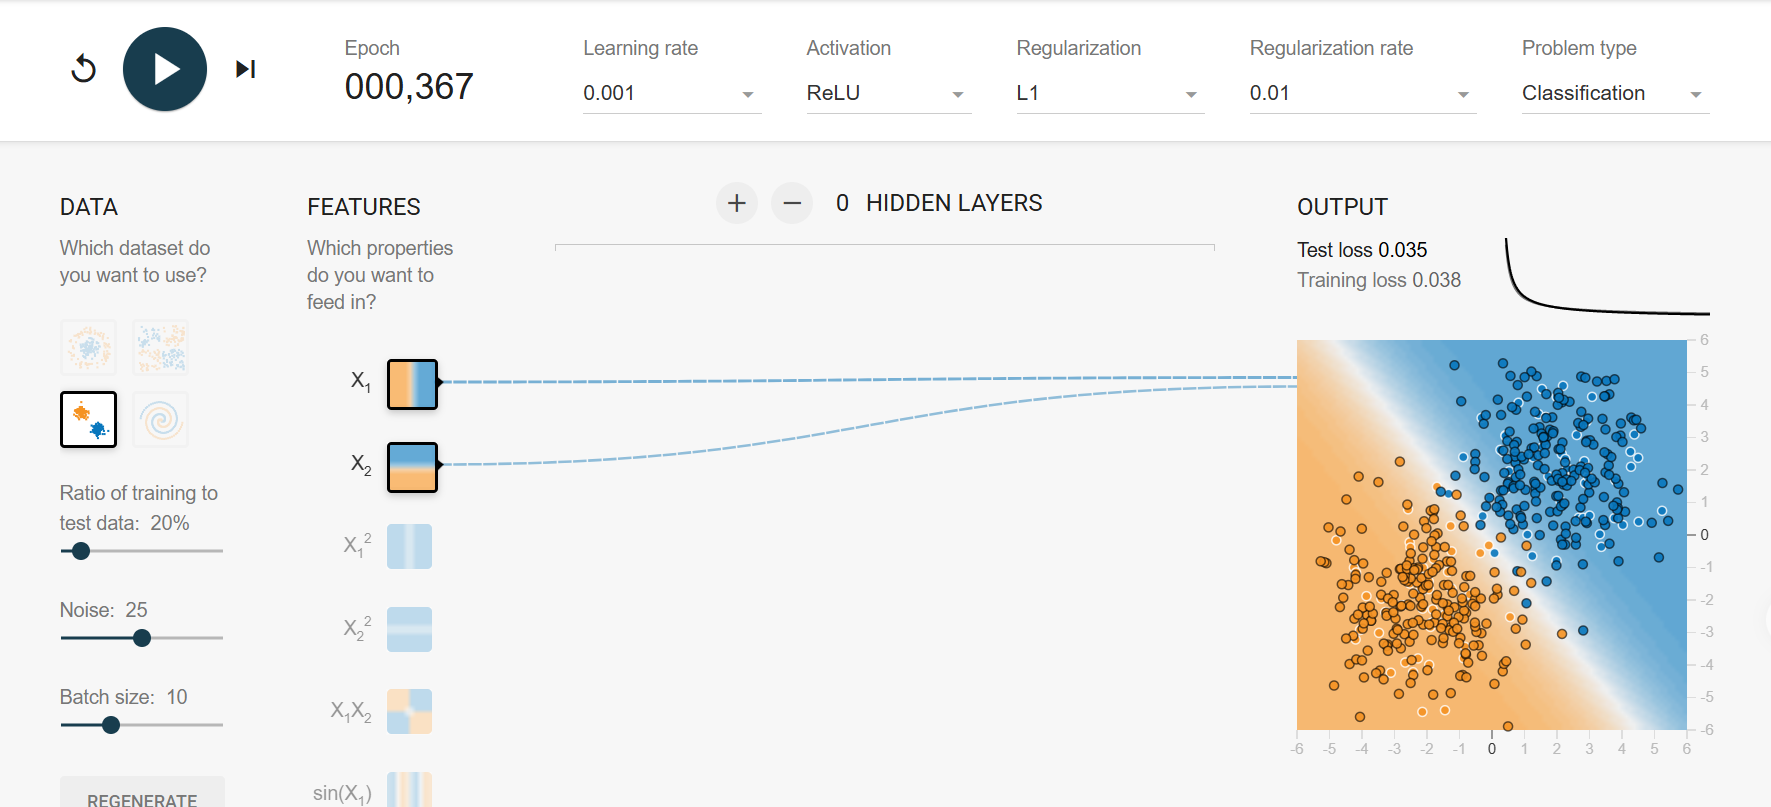

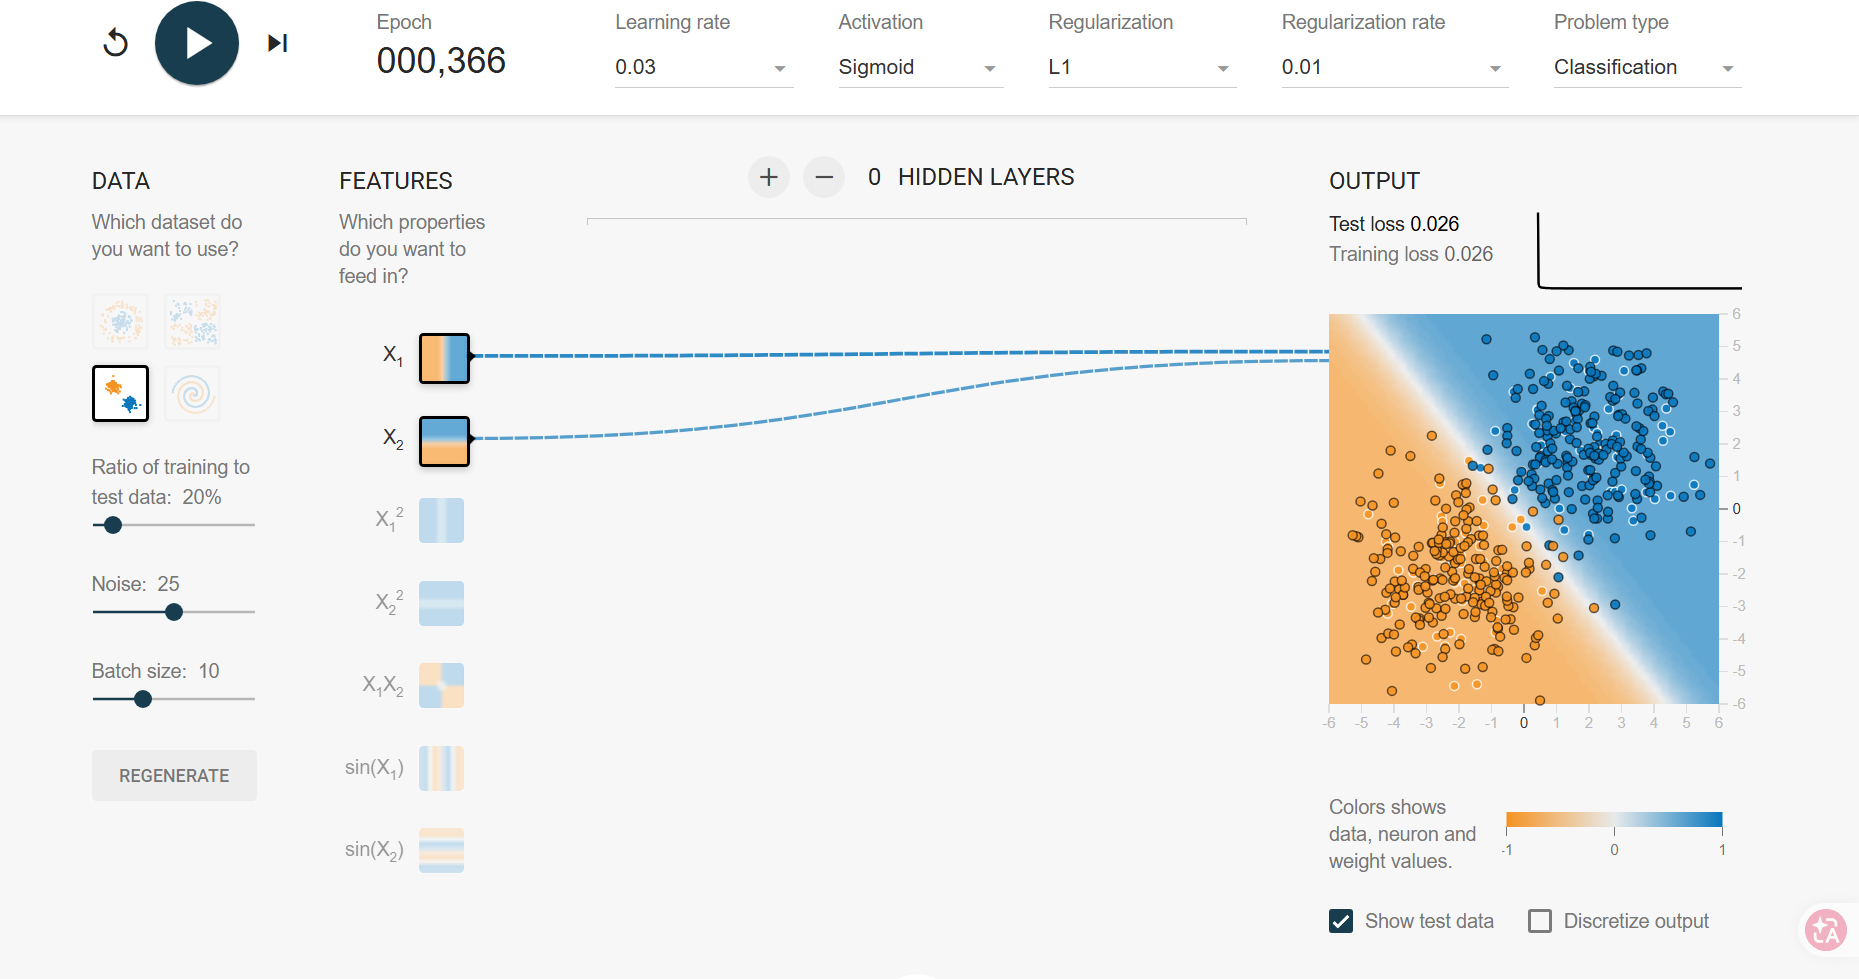

---
#### ヒント

- 3層パーセプトロンの設定で，Activation（活性化関数）を ReLU にしてみましょう．ReLU(x)=max(x, 0)は x が負のときだけ 0 にする関数です．
- [この例](https://playground.tensorflow.org/#activation=relu&batchSize=10&dataset=circle&regDataset=reg-plane&learningRate=0.03&regularizationRate=0&noise=0&networkShape=3&seed=0.27615&showTestData=false&discretize=false&percTrainData=50&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false)のように，多角形の領域が作られることがあります．その理由を考えましょう．
- この3層パーセプトロンは，2入力1出力の関数です．[そのグラフと等高線を描けます](https://www.wolframalpha.com/input?i=plot%28+%28+-1.2*max%281.2x%2B0.35y-0.33%2C+0%29+-+1.3*max%28-0.22x-1.2y-0.61%2C+0%29+-+1.3*max%28-0.93x%2B0.81y-0.58%2C0%29++%29+for+x+from+-6+to+6+for+y+from+-6+to+6%29)　[[出典]](https://datascience.stackexchange.com/questions/76022/what-does-the-descision-boundary-of-a-relu-look-like)．

----
## 発展課題（任意）

Playgroundの右上に表示される "Test loss"，"Training loss" について考えましょう．


In [1]:
#@title 2次元に2クラスを描く `plot2cls` を定義します（理解不要）．
!wget -q -N https://gist.githubusercontent.com/tsakai-g/1920bc185be0c497579968e00a9b3674/raw/plot2cls.py
%run plot2cls.py

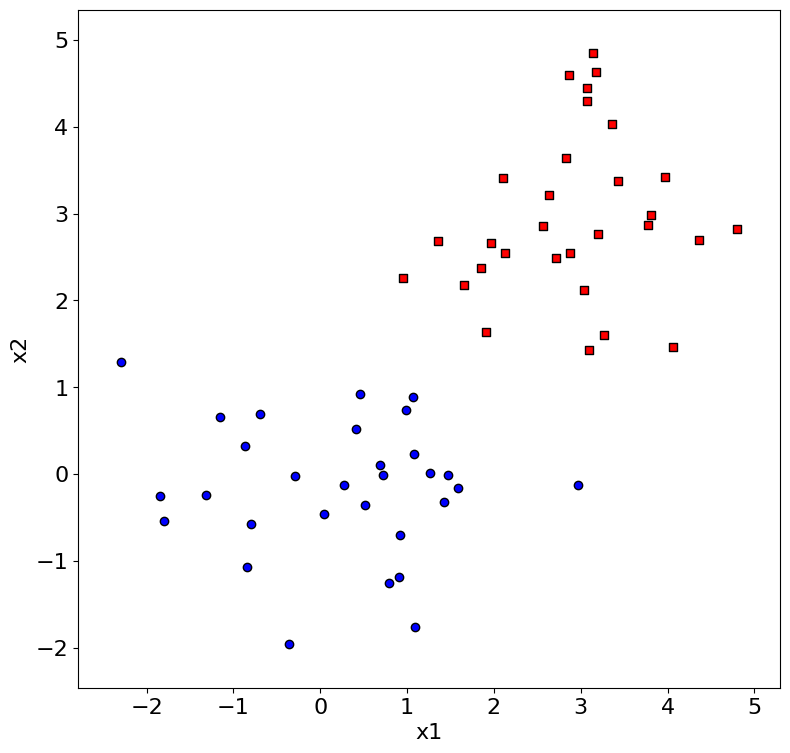

In [2]:
#@title 例題用のデータを生成します．
import numpy as np
npos = 30
nneg = 30
np.random.seed(321)
X = np.r_[np.random.randn(npos, 2) + [3, 3], np.random.randn(nneg, 2)]
# [1,1,...,1,-1,-1,...,-1]
y = np.array([1] * npos + [-1] * nneg)

plot2cls(X, y).plot_data()

### 損失関数を定義します．

In [3]:
import numpy as np

def LogisticLoss(y, g):
    return np.mean(np.log(1.0 + np.exp(-y*g)))

def HingeLoss(y, g):
    return np.mean(np.maximum(1.0 - y*g, 0.0))

# 線形識別関数
def g(X, w):
    return w[0] + np.dot(X, w[1:])

### $[w_0, w_1, w_2]^\top$はパーセプトロンの重みです．表示される損失関数の値がなるべく小さくなるように調整してください．
    1. どのようなとき，損失が大きく・小さくなりますか．

（ここに回答を書いてください）


    2. w0, w1, w2 によって決定境界はどのように変わりますか．

（ここに回答を書いてください）






 Logistic loss = 0.534498,  Hinge loss =0.642039 




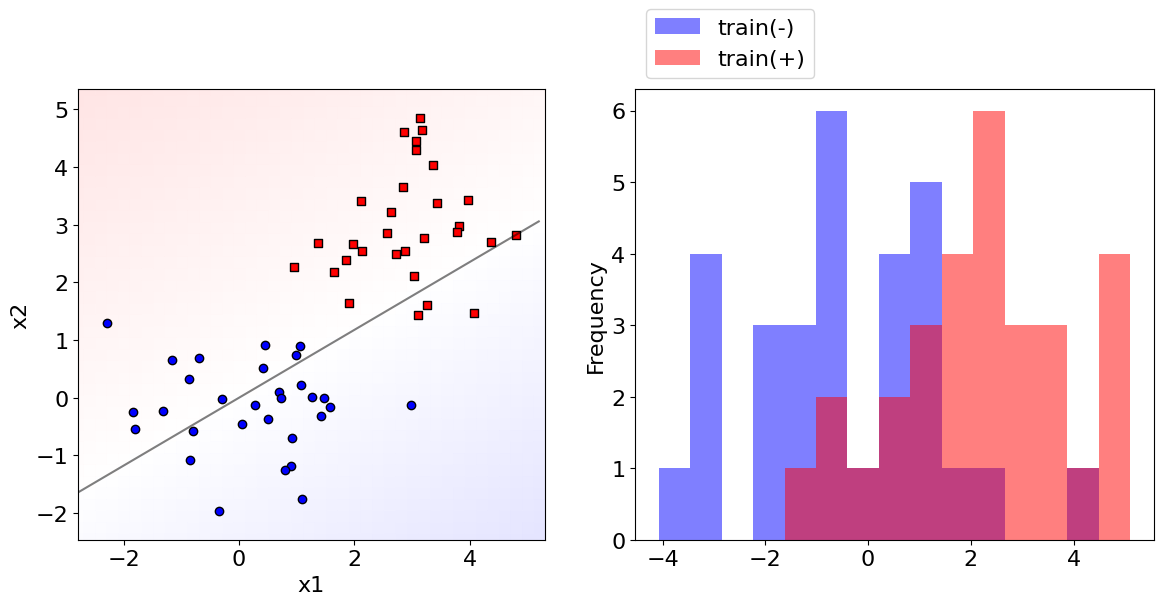

In [5]:
#@title {run: "auto"}
w0 = 0 #@param{type:"slider", min:-5, max:5, step:0.1}
w1 = -1 #@param{type:"slider", min:-5, max:5, step:0.1}
w2 = 1.7 #@param{type:"slider", min:-5, max:5, step:0.1}
w = np.array( [w0, w1, w2] )

ll = LogisticLoss(y, g(X, w))
hl = HingeLoss(y, g(X, w))
print('\n'*2, "Logistic loss = %f,  Hinge loss =%f" % (ll, hl), '\n'*2)
plotter = plot2cls(X, y, lambda X: g(X, w), levels={0.0:'-'}, dx=0.2)
plotter.plot_clf()
#plotter.plot_data()
#plotter.plot_hist()